
# 26S1_AI6124 Project
Created by A/Prof Kai Keng ANG (kkang@a-star.edu.sg, kkang@ntu.edu.sg). Last modified 2 Oct 2026

Submitted by: [Student Name] Mat ID: [Student ID]

# Instructions
Enter your name according to NTU Learn, and your student ID above. Do not include the square brackets. Please save the file as "AI6124\_Project\_[Student name].ipynb" and submit in NTU Learn. Eg. "AI6124\_Project\_James\_Tan.ipynb"



## Objective

After completing this project, you will know:

Part 1: (Code provided)
* How to download any stock prices or commodity to work on
* How to compute buy sell signals on the stock
* How to measure portfolio performance from profit and loss based on buy and sell signals on the stock

Part 2: (To be coded by student)
* How to choose parameters to optimize profits, and explore different trading strategies
* How to apply computational intelligent methods to choose parameters of trading strategies on training data set, then apply to test data set
* How to benchmark the portfolio performance of  computational intelligent methods

Part 3: (To be coded by student)
* How to apply computational intelligent methods to measure the performance of the prediction
* How to train an initial model
* Bonus: How to improve the prediction on the initial model using another dataset such as commodity gold or crude oil, or use GDELT data, a database that included world events.
* How to interpret and explain the computational intelligent method in predicting the stock prices
* How to apply the stock price prediction to help increase profits, and benchmark the portfolio performance with and without prediction

Code for part 1 of first 3 objectives listed above are provide for you to kick start your project. You will have to complete part 2 and part 3 for the project. For more details on how to predict stock prices and compute the portfolio performance, refer (Ang & Quek, 2006).


## References

Ang, K. K., & Quek, C. (2006). Stock Trading Using RSPOP: A Novel Rough Set-Based Neuro-Fuzzy Approach. IEEE Trans. Neural Netw., 17(5), 1301-1315. doi:http://dx.doi.org/10.1109/TNN.2006.875996

Fasanya, I. O., Adekoya, O., & Sonola, R. (2023). Forecasting stock prices with commodity prices: New evidence from Feasible Quasi Generalized Least Squares (FQGLS) with non-linearities. Economic Systems, 47(2), 101043. doi: https://doi.org/10.1016/j.ecosys.2022.101043


## Introduction

First we install the yahoo finance library

This library is used to download stock prices into pandas data frame.

In [ ]:
!pip install pandas
!pip install yfinance
!pip install yahoofinancials
!pip install mpld3


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.9/51.9 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for yahoofinancials: filename=yahoofinancials-1.20-py3-none-any.whl size=38677 sha256=7fa9cb9899910a0624652ff8cfac17b1baeb41c0964d0f00bf7e5586610045dc
  Stored in directory: /root/.cache/pip/wheels/bc/e1/66/a57b967b9074fc5dafa46c262e12d48c8b17f329040f6d88e4
Successfully built yahoofinancials
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 9.6 MB/s eta 0:00:00


Then we import the necessary libraries

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from yahoofinancials import YahooFinancials
%matplotlib inline
import mpld3
mpld3.enable_notebook()

# 1. Download historical prices

Historical data can be downloaded from Yahoo Finance using the yfinance library. You can look up how to use this library online, such as https://algotrading101.com/learn/yfinance-guide/. Becareful not to download too many datasets to try. It is free for a few downloads, but you may need to pay for API after a few downloads. So save the data after the download for further processing.


## 1.1. Stock price

You can look up the Singapore stock price symbol from https://sg.finance.yahoo.com/lookup. Pick a Singapore stock price to download. One example is DBS Group Holdings Ltd (D05.SI). Another example of a stock price is Real Estate Investment Trust (REIT). You will need the symbol to download in the code below, such as Keppel REIT (K71U.SI). The following is how you can download the historical prices.

In [ ]:
stock_df = yf.download('K71U.SI')
stock_df.head()

/tmp/ipykernel_1444/2515885453.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_df = yf.download('K71U.SI')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,K71U.SI,K71U.SI,K71U.SI,K71U.SI,K71U.SI
Date,,,,,
2026-09-07,0.870,0.875,0.860,0.860,12061000
2026-09-08,0.860,0.870,0.855,0.870,12175900
2026-09-09,0.855,0.860,0.850,0.855,10575800
2026-09-10,0.850,0.855,0.850,0.855,6278800
2026-09-11,0.850,0.850,0.840,0.850,15295700


Note that the download function only downloaded a certain range of dates. Alternatively, you can also use the ticker function to download the entire stock price. Ticker also allows you to download additional data. After you downloaded the stock price, you can also plot the data.

<Axes: title={'center': "Keppel REIT's price"}, xlabel='Date'>

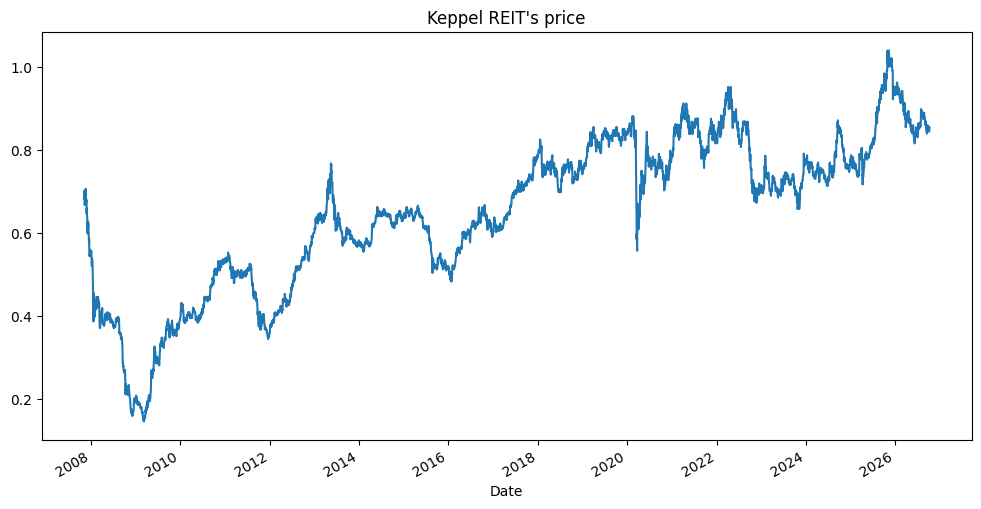

In [ ]:
ticker = yf.Ticker('K71U.SI')
#ticker = yf.Ticker('^STI')
stock_df = ticker.history(period="max")
#start_date = '1988-01-01'
#end_date = '2025-03-01'
#stock_df = ticker.history(start=start_date, end=end_date)
figure(figsize=(12, 6))
stock_df['Close'].plot(title="Keppel REIT's price")


Similar to download function, you can look at the data. Notice the additional columns downloaded.

In [ ]:
stock_df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2007-11-06 00:00:00+08:00,0.685949,0.685949,0.680713,0.683331,119821,0.0,0.0
2007-11-07 00:00:00+08:00,0.683331,0.704276,0.683331,0.696421,47684,0.0,0.0
2007-11-09 00:00:00+08:00,0.706894,0.706894,0.691185,0.701658,35457,0.0,0.0
2007-11-12 00:00:00+08:00,0.691186,0.691186,0.667622,0.667622,121044,0.0,0.0
2007-11-13 00:00:00+08:00,0.670240,0.675477,0.667622,0.670240,118598,0.0,0.0


You can also look at the only the dividends using the code below.

In [ ]:
ticker.dividends

,Dividends
Date,
2008-01-29 00:00:00+08:00,0.038285
2008-05-05 00:00:00+08:00,0.034856
2008-08-01 00:00:00+08:00,0.015347
2009-01-23 00:00:00+08:00,0.041387
2009-07-27 00:00:00+08:00,0.040734
...,...
2025-02-05 00:00:00+08:00,0.027946
2025-08-06 00:00:00+08:00,0.027148
2025-10-15 00:00:00+08:00,0.016269


## 1.2 Commodity price

Commodity prices can also be downloaded from Yahoo Finance. This is different from stock prices in Yahoo Finance, as these are available as commodities future prices. In trading, a commodity future is a legally binding agreement to buy or sell a specific commodity at a predetermined price on a future date.

Pick a commodity future price to download. An example is Gold (GC=F). Note that this is in USD, not SGD. If you are using Commodity to improve the stock price prediction, please ensure that the dates of the time series matches.


In [ ]:
ticker = yf.Ticker('GC=F')
commodity_df = ticker.history(period="max")
commodity_df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2000-08-30 00:00:00-04:00,273.899994,273.899994,273.899994,273.899994,0,0.0,0.0
2000-08-31 00:00:00-04:00,274.799988,278.299988,274.799988,278.299988,0,0.0,0.0
2000-09-01 00:00:00-04:00,277.000000,277.000000,277.000000,277.000000,0,0.0,0.0
2000-09-05 00:00:00-04:00,275.799988,275.799988,275.799988,275.799988,2,0.0,0.0
2000-09-06 00:00:00-04:00,274.200012,274.200012,274.200012,274.200012,0,0.0,0.0


After you downloaded the commodity price, you can also plot the data. Note that commodity may be used to improve the stock price prediction (Fasanya et al., 2023), but this is an optional bonus part of the project. Attempt this only when you completed the basic parts of the project.

<Axes: title={'center': 'Gold price'}, xlabel='Date'>

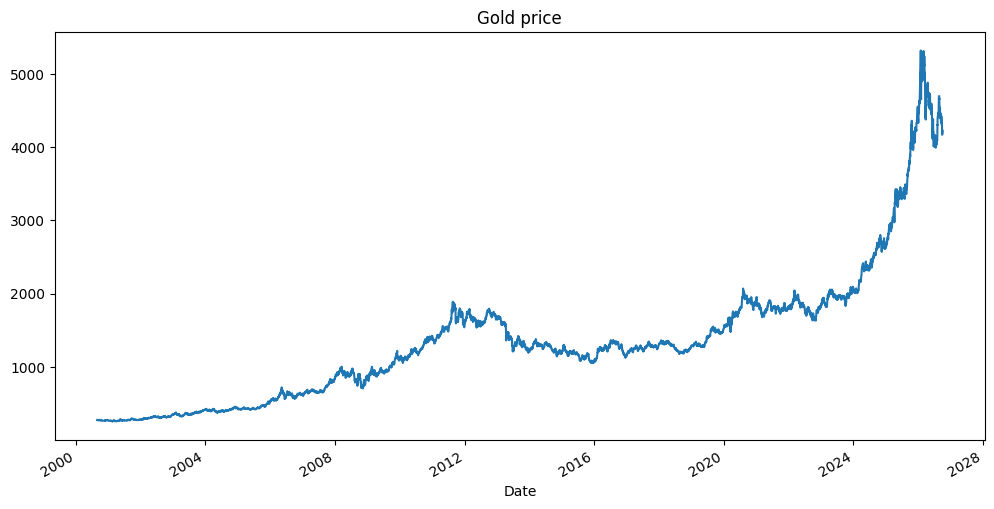

In [ ]:
figure(figsize=(12, 6))
commodity_df['Close'].plot(title="Gold price")

# 2. Computing trade signals

There are different types of moving averages, such as simple moving average, weighted moving average or exponential moving average. The
difference between the types is how the average is computed based on the weight assigned to data points. Simple moving average can be computed by simply taking the mean of the data points. The period to compute the moving average is a parameter. You can have a 200 days simple moving average, a 5 days simple moving average etc. Here' we compute a fast 20 days and slow 100 days moving average on the close price.

In [ ]:
df=stock_df
# create 20 days simple moving average column
df['Fast_SMA'] = df['Close'].rolling(window = 20, min_periods = 1).mean()
# create 50 days simple moving average column
df['Slow_SMA'] = df['Close'].rolling(window = 100, min_periods = 1).mean()
# display first few rows
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Fast_SMA,Slow_SMA
Date,,,,,,,,,
2007-11-06 00:00:00+08:00,0.722817,0.722817,0.717299,0.720058,119821,0.0,0.0,0.720058,0.720058
2007-11-07 00:00:00+08:00,0.720058,0.742129,0.720058,0.733852,47684,0.0,0.0,0.726955,0.726955
2007-11-09 00:00:00+08:00,0.744888,0.744888,0.728334,0.739370,35457,0.0,0.0,0.731093,0.731093
2007-11-12 00:00:00+08:00,0.728334,0.728334,0.703505,0.703505,121044,0.0,0.0,0.724196,0.724196
2007-11-13 00:00:00+08:00,0.706264,0.711781,0.703505,0.706264,118598,0.0,0.0,0.720609,0.720609


There many moving average strategies that can be developed to generate trade signals. here we will use a simple moving average crossover strategy based on the SMAs we computed. A moving average can be use to indicate price trends. A crossover occurs when a faster or shorter moving average, such as the 20 days SMA crosses a slower or longer moving average, such as the 100 days SMA. This crossover  point can be used as a  indicator to buy or sell a stock.

First we create a new column ‘Signal’ such that if Fast_SMA is greater than Slow_SMA then set to 1 else set to 0.


In [ ]:
df['Signal'] = 0.0
df['Signal'] = np.where(df['Fast_SMA'] > df['Slow_SMA'], 1.0, 0.0)

We now need to generate the buy and sell from the ‘Signal’ values. Crossover happens when the Fast_SMA and the Slow_SMA cross,  the ‘Signal’ changes from 0 to 1, or from 1 to 0. Thus we can just create a ‘Position’ value to indicate a day-to-day difference of the ‘Signal’ column.

‘Position’ = 1 implies that Signal changed from 0 to 1, meaning a faster moving average has crossed a slower moving average. This indicates a bull or up trend in the price and thus this is a buy signal.

‘Position’ = -1 implies that  Signal changed from 1 to 0, meaning a faster moving average has crossed below a slower moving average. This indicates a bear or down trend in the price and thus this is a sell signal.

In [ ]:
df['Position'] = df['Signal'].diff()
# Need to set the first row of Position to 0. Otherwise it is nan from diff function.
df['Position'].iloc[0]=0
# display first few rows
df.head()


/tmp/ipython-input-394523951.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['Position'].iloc[0]=0
/tmp/ipython-input-394523951.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the 

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Fast_SMA,Slow_SMA,Signal,Position
Date,,,,,,,,,,,
2007-11-06 00:00:00+08:00,0.722817,0.722817,0.717299,0.720058,119821,0.0,0.0,0.720058,0.720058,0.0,0.0
2007-11-07 00:00:00+08:00,0.720058,0.742129,0.720058,0.733852,47684,0.0,0.0,0.726955,0.726955,0.0,0.0
2007-11-09 00:00:00+08:00,0.744888,0.744888,0.728334,0.739370,35457,0.0,0.0,0.731093,0.731093,0.0,0.0
2007-11-12 00:00:00+08:00,0.728334,0.728334,0.703505,0.703505,121044,0.0,0.0,0.724196,0.724196,0.0,0.0
2007-11-13 00:00:00+08:00,0.706264,0.711781,0.703505,0.706264,118598,0.0,0.0,0.720609,0.720609,0.0,0.0


<Axes: xlabel='Date'>

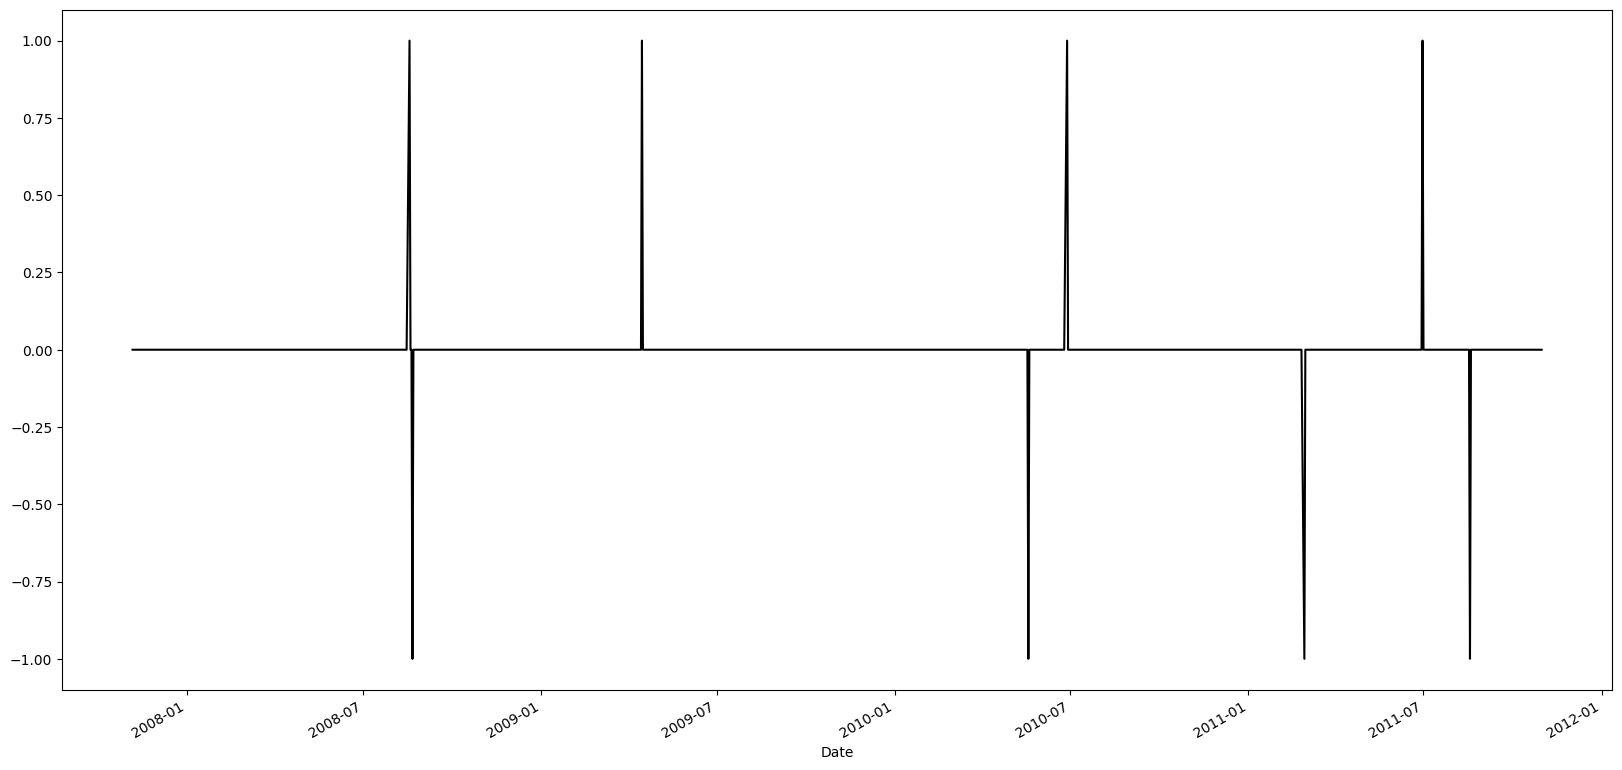

In [ ]:
# Plot the positions
plt.figure(figsize = (20,10))
df.iloc[0:1000]['Position'].plot(color = 'k', label= 'Position')


Next we need to change the position signal to trade signals. Although position can give us this information, we want the change in the trade signal, which is the change from -1 to 1 to indicate a buy, and 1 to -1 to indicate a sell. This is for computing the Multiplicative Portfolio Returns.

0.0


<Axes: xlabel='Date'>

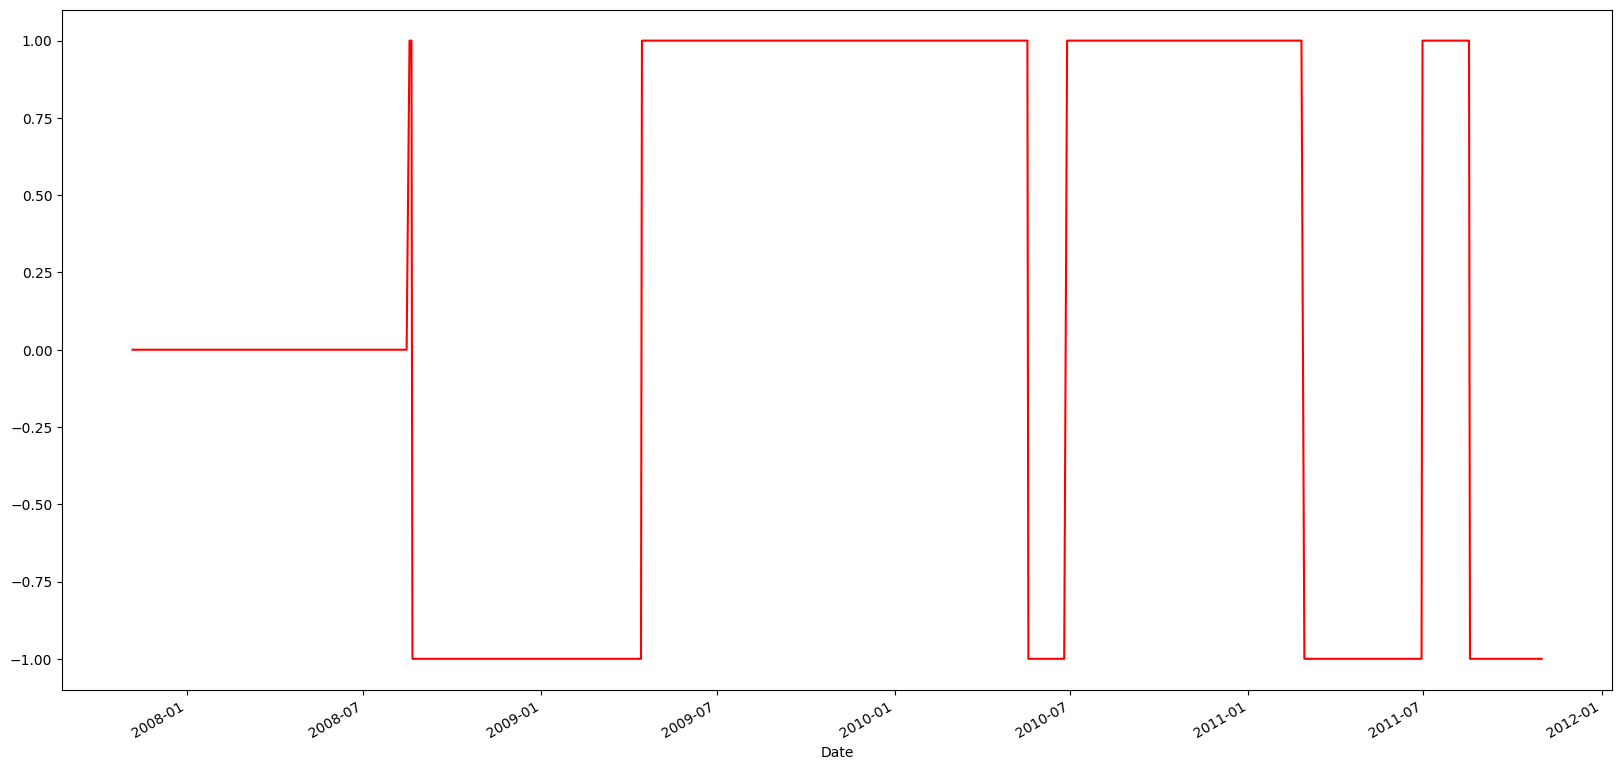

In [ ]:
plt.figure(figsize = (20,10))
df['Trade'] = df['Position']
prevrow = df.iloc[0]
print(prevrow['Position'])
for index, row in df.iloc[1:].iterrows():
  if row['Trade']==0:
    if prevrow['Trade']!=0:
      df.at[index,'Trade']=prevrow['Trade']
      row['Trade']=prevrow['Trade']
  prevrow=row
df.iloc[0:1000]['Trade'].plot(color = 'r', label= 'Trade')

/tmp/ipython-input-1010064138.py:8: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(df[df['Position'] == 1].index, df['Fast_SMA'][df['Position'] == 1], '^', markersize = 15, color = 'g', label = 'buy')


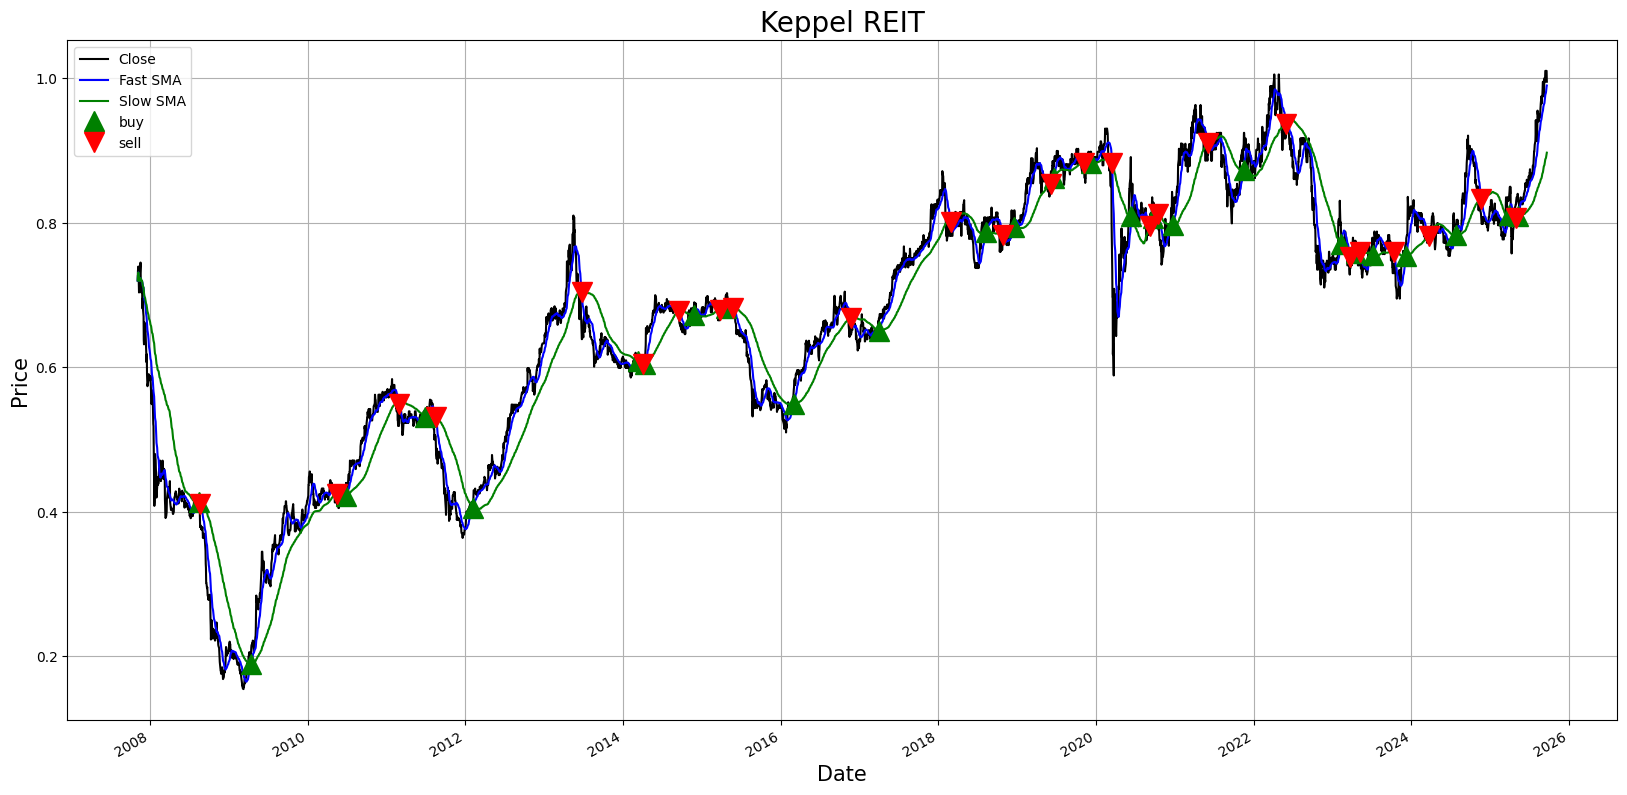

In [ ]:
# plot close price, Fast and Slow simple moving averages
def plotprice(df):
  plt.figure(figsize = (20,10))
  df['Close'].plot(color = 'k', label= 'Close')
  df['Fast_SMA'].plot(color = 'b', label = 'Fast SMA')
  df['Slow_SMA'].plot(color = 'g', label = 'Slow SMA')
  # plot buy signals
  plt.plot(df[df['Position'] == 1].index, df['Fast_SMA'][df['Position'] == 1], '^', markersize = 15, color = 'g', label = 'buy')
  # plot sell signals
  plt.plot(df[df['Position'] == -1].index, df['Fast_SMA'][df['Position'] == -1], 'v', markersize = 15, color = 'r', label = 'sell')
  plt.ylabel('Price', fontsize = 15 )
  plt.xlabel('Date', fontsize = 15 )
  plt.title('Keppel REIT', fontsize = 20)
  plt.legend()
  plt.grid()
  plt.show()

plotprice(df)

It is not very clear in the plot above since it included the prices of many years. Lets zoom in to take a closer look.

/tmp/ipython-input-1010064138.py:8: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(df[df['Position'] == 1].index, df['Fast_SMA'][df['Position'] == 1], '^', markersize = 15, color = 'g', label = 'buy')


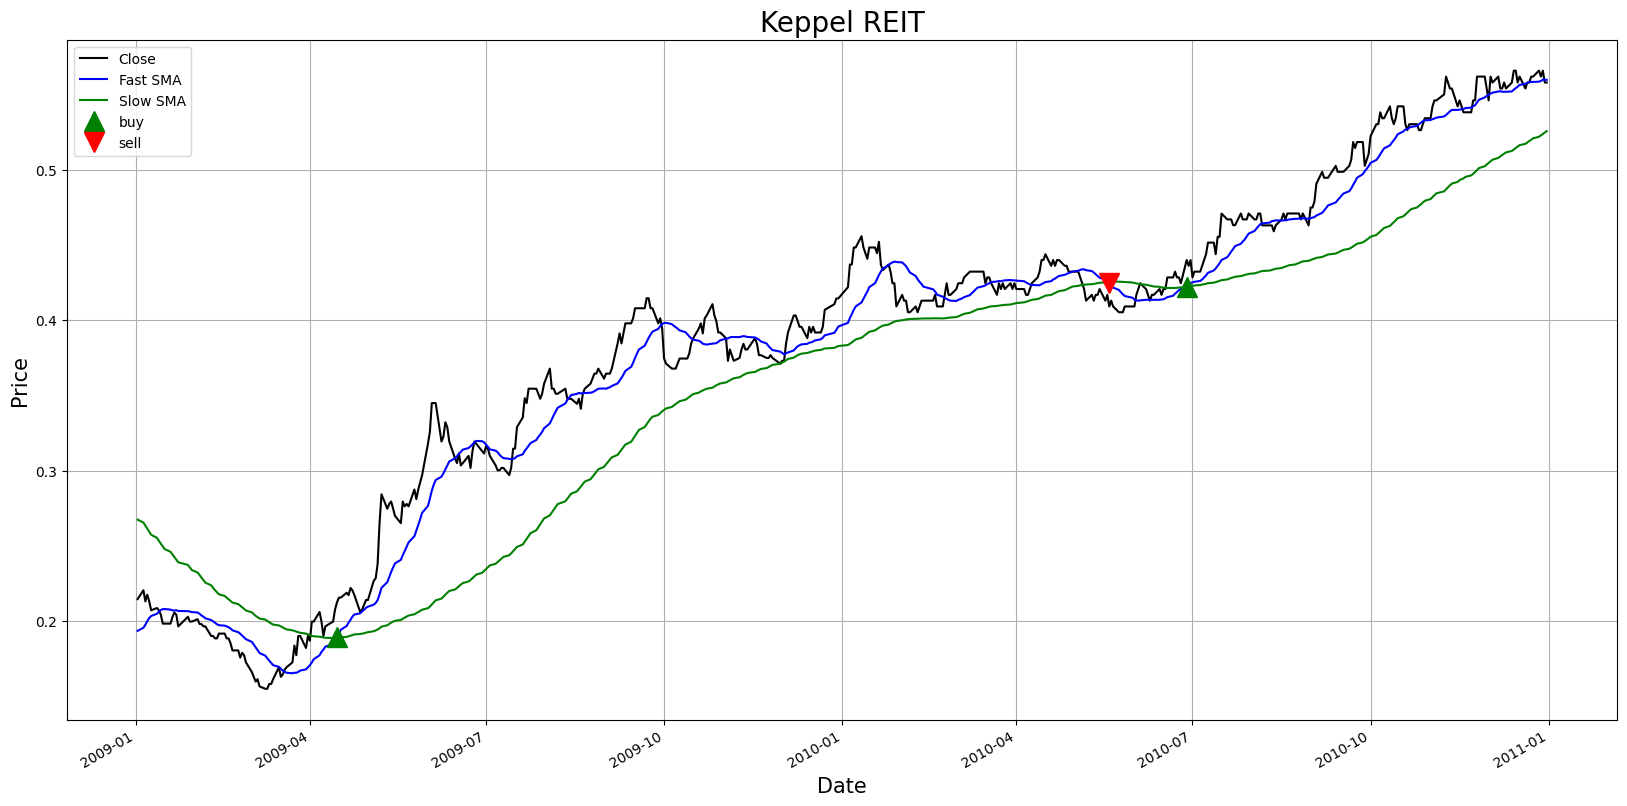

In [ ]:
sdf=df.loc['2009-01-01':'2010-12-31']
plotprice(sdf)


Notice that there is a buy at Apr 2009, but the buy and sell are performed at almost the same price at around May 2010. Since each trade incurs a transaction cost, trades at around the same price will result in losses. Hence a better trading strategy can be implemented, such as the introduction of a moving average band to reduce the number of trades around the same price. Refer to the paper on this for more details.

# 3. Computing portfolio returns

The computation of portfolio returns in this section is based on the multiplicative returns given by (refer equation 11 of the reference paper)

$\begin{equation}
R(T)=\{1+F(T-1)r(T)\}\{1-\delta|F(T)-F(T-1)|\}
\end{equation}$

where $r(T)=(y(T)/y(T-1))-1$; $y(T)$ is the closing price at time $T$; $F(T)$ is the action from the trading system; and $\delta$ is the transaction rate.

The multplicative profits $R$ can computed using

$\begin{equation}
R=\prod\limits_{T = 1}^{n} R(T)
\end{equation}$

where $n$ is the total number of time points.


0.0


<Axes: xlabel='Date'>

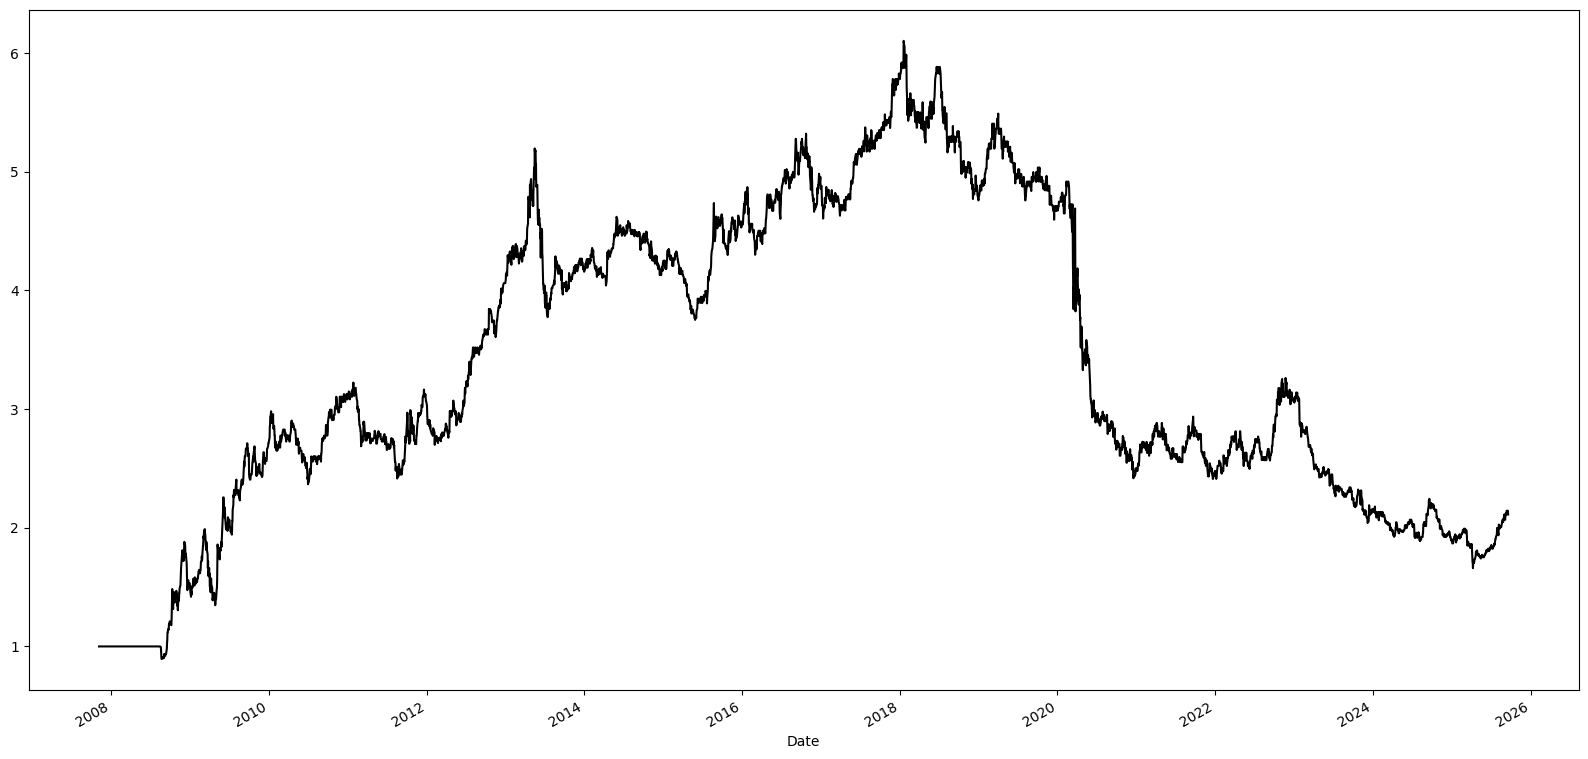

In [ ]:
df['Returns']=1.0
print(df.iloc[1]['Trade'])

def computereturns(tdf,trate):
  prevrow = tdf.iloc[0]
  returncol=tdf.columns.get_loc('Returns')
  for i in range(len(tdf)):
    if i==0:
      prev_i=i
    else:
      prevrow=tdf.iloc[prev_i]
      row=tdf.iloc[i]
      rt=(row['Close']/prevrow['Close'])-1
      t=prevrow['Returns']*(1+prevrow['Trade']*rt)*(1-trate*abs(row['Trade']-prevrow['Trade']))
      tdf.iat[i,returncol]=t
      prev_i=i
  return tdf

df=computereturns(df,0.005)
plt.figure(figsize = (20,10))
#df.iloc[1:1000]['Returns'].plot(color = 'k', label= 'Returns')
df['Returns'].plot(color = 'k', label= 'Returns')


Notice in the above plot that some times the portfolio returns dropped below 1.0, some times it rises above 1.0 or even as high as 5.0. Hence this shows that the choice of trading strategy and parameters are very important to yield either profits or losses. Above 1.0 indicates there is overall profit. Less than 1.0 indicates there is a loss.
